In [1]:
import pandas as pd
import folium
import matplotlib.pyplot as plt

**Importing the CSV file which contains the Crash Data in New Brunswick from 2025**

In [2]:
df=pd.read_csv("Crash.csv")

**Creating Intersection Column**

In [3]:
inter = df[df['intersectstreetname'].notna()].copy()
inter['streetname'] = inter['streetname'].str.replace(" Secondary","")
inter['intersectstreetname'] = inter['intersectstreetname'].str.replace(" Secondary","")

In [4]:
inter['intersection'] = inter.apply(lambda row: " & ".join(sorted([row['streetname'], row['intersectstreetname']])), axis=1)

**Creating dataframe to get the hotspots for Crashes**

In [5]:
spots = inter.groupby('intersection')[['latitude','longitude']].mean()

In [6]:
spots['crashes'] = inter.groupby('intersection').size()

In [7]:
spots = spots.sort_values('crashes',ascending=False)

**Mapping crash hotspots**

In [8]:
top = spots.head(15)
m = folium.Map(location=[40.49, -74.445], zoom_start=14,tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
attr="Esri")
for name, row in top.iterrows():
    folium.CircleMarker(
        location=[ row['latitude'] , row['longitude'] ],
        radius= row['crashes']/5,
        popup= f"{name}: {row['crashes']} crashes" ,
        fill=True ,
        color="red" ,
        fill_opacity=0.5,
        tooltip=name.replace("`","'")
    ).add_to(m)

**Creating bar graph for crashes per day and crashes per hour**

In [9]:
days= ['Sunday','Monday','Tuesday','Wednesday','Thursday','Friday','Saturday']

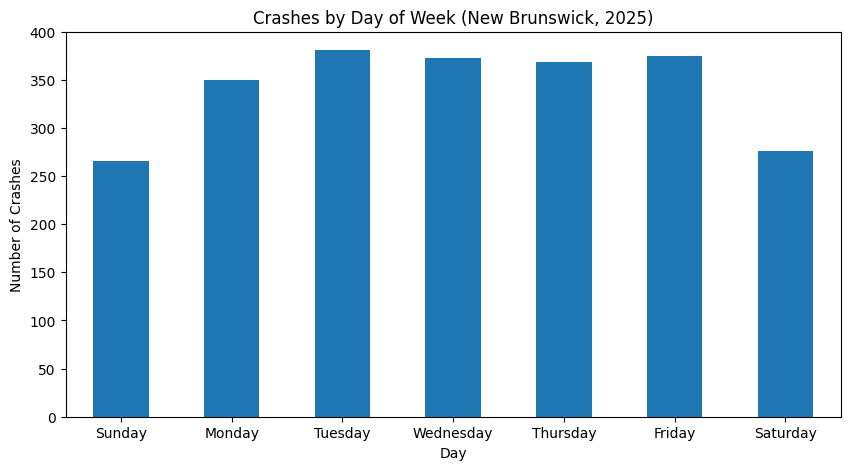

In [10]:
ax = df['Day of Week'].value_counts().reindex(days).plot(kind='bar',figsize=(10, 5),title="Crashes by Day of Week (New Brunswick, 2025)",xlabel='Day',ylabel="Number of Crashes",rot=0)

In [11]:
ax.get_figure().savefig("days.png", bbox_inches="tight")

In [12]:
df['hour'] = df['timeofcrash'] // 100

<Axes: title={'center': 'Crashes Per Hour (New Brunswick, 2025)'}, xlabel='Hour (24-hour clock)', ylabel='Number of Crashes'>

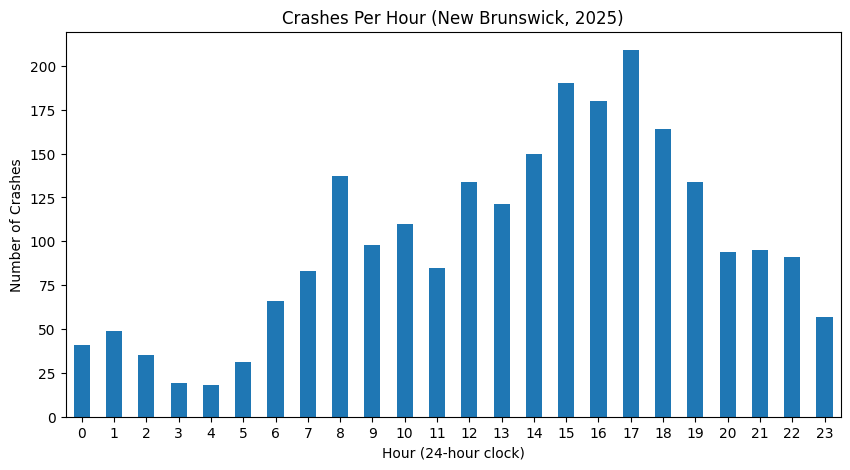

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
df['hour'].value_counts().sort_index().plot(ax=ax,kind='bar',title="Crashes Per Hour (New Brunswick, 2025)",rot=0,xlabel='Hour (24-hour clock)',ylabel='Number of Crashes')

In [14]:
ax.get_figure().savefig("hours.png", bbox_inches="tight")

**Creating dataframe to get accidents where Pedestrians were struck**

In [15]:
peds = df[df['Crash Type'] == "Pedestrian"]

In [16]:
peds['Highest Injury Severity Rating'].value_counts()

Highest Injury Severity Rating
No Apparent Injury (O)          30
Suspected Minor Injury (B)      25
Possible Injury (C)             20
Suspected Serious Injury (A)    11
Fatal Injury (K)                 1
Name: count, dtype: int64

In [17]:
severitylevel = {"Fatal Injury (K)": "black", "Suspected Serious Injury (A)": "darkred", "Possible Injury (C)": "Yellow", "Suspected Minor Injury (B)": "Orange", "No Apparent Injury (O)": "green", }

**Mapping Pedestrian involved accidents**

In [18]:
for name, row in peds.iterrows():
    folium.CircleMarker(
        location=[ row['latitude'] , row['longitude'] ],
        radius= 5,
        popup= f"{row['streetname']}: {row['Highest Injury Severity Rating']}" ,
        fill=True ,
        color=severitylevel[row['Highest Injury Severity Rating']] ,
        fill_opacity=1,
        tooltip=row['streetname'].replace("`","'"),
    ).add_to(m)

In [19]:
m.save("map.html")